# Imports 

In [1]:
import pandas as pd
import numpy as np
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split, StratifiedShuffleSplit, RandomizedSearchCV
from sklearn.preprocessing import RobustScaler, MinMaxScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.neighbors import KNeighborsClassifier
from skopt import BayesSearchCV
from sklearn.metrics import confusion_matrix
import joblib
from sklvq import GLVQ
import matplotlib.pyplot as plt
from sklearn.ensemble import AdaBoostClassifier

random_state=42

-----

# Functions

In [2]:
def train_validation_test_split(
        X, y, validation_size=0.1,
        test_size=0.1, random_state=42):
    
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state, stratify=y
    )

    X_train, X_valid, y_train, y_valid = train_test_split(
        X_train, y_train,
        test_size=validation_size / (1 - test_size),
        random_state=random_state,
        stratify=y_train,
    )
    return X_train, X_valid, X_test, y_train, y_valid, y_test

In [3]:
from scipy import stats
def confidence_interval(data, confidence=0.95):
    mean = np.mean(data)
    n = len(data)
    std_err = np.std(data, ddof=1) / np.sqrt(n)
    t_value = stats.t.ppf((1 + confidence) / 2, n - 1)
    margin_of_error = t_value * std_err

    return f"{mean:.5f} ± {margin_of_error:.5f}"

In [37]:
def report_model_performance(model, X_train, X_valid, X_test, y_train, y_valid, y_test):
    
    accuracy_best_param_cv = np.array([model.steps[-1][-1].cv_results_[f"split{i}_test_Accuracy"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]
    precision_best_param_cv = np.array([model.steps[-1][-1].cv_results_[f"split{i}_test_Precision"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]
    recall_best_param_cv = np.array([model.steps[-1][-1].cv_results_[f"split{i}_test_Recall"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]
    f1_best_param_cv = np.array([model.steps[-1][-1].cv_results_[f"split{i}_test_F1"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]
    roc_best_param_cv = np.array([model.steps[-1][-1].cv_results_[f"split{i}_test_ROC-AUC"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]

    best_param = model.steps[-1][-1].best_params_
    print(f"Best parameters: {best_param}")
    print(f"Cross Validation accuracy Array: {accuracy_best_param_cv}")
    print(f"Validation accuracy: {confidence_interval(accuracy_best_param_cv)}")
    
    print(f"Cross Validation precision Array: {precision_best_param_cv}")
    print(f"Validation precision: {confidence_interval(precision_best_param_cv)}")
    
    print(f"Cross Validation recall Array: {recall_best_param_cv}")
    print(f"Validation recall: {confidence_interval(recall_best_param_cv)}")
    
    print(f"Cross Validation f1 Array: {f1_best_param_cv}")
    print(f"Validation f1: {confidence_interval(f1_best_param_cv)}")
    
    print(f"Cross Validation roc Array: {roc_best_param_cv}")
    print(f"Validation roc: {confidence_interval(roc_best_param_cv)}")
    
    print()
    y_train_pred = model.predict(X_train)
    y_valid_pred = model.predict(X_valid)
    y_test_pred = model.predict(X_test)
    
    y_train_proba = model.predict_proba(X_train)
    y_valid_proba = model.predict_proba(X_valid)
    y_test_proba = model.predict_proba(X_test)
    print("===> Training performance")
    print(classification_report(y_train, y_train_pred, digits=5))
    print(f"Train ROC-AUC: {roc_auc_score(y_train, y_train_proba, multi_class='ovr'):.3f}")
    print("===> Validation performance")
    print(classification_report(y_valid, y_valid_pred, digits=5))
    print(f"Validation ROC-AUC: {roc_auc_score(y_valid, y_valid_proba, multi_class='ovr'):.3f}")
    print("===> Test performance")
    print(classification_report(y_test, y_test_pred, digits=5))
    print(f"Test ROC-AUC: {roc_auc_score(y_test, y_test_proba, multi_class='ovr'):.3f}")
    
    with sns.plotting_context("notebook", font_scale=1.5):
        conf_matrix = confusion_matrix(y_train, y_train_pred)
        sns.heatmap(conf_matrix, annot=True, fmt="d")
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.title("Train Confusion Matrix")
        plt.show()

    with sns.plotting_context("notebook", font_scale=1.5):
        conf_matrix = confusion_matrix(y_valid, y_valid_pred)
        sns.heatmap(conf_matrix, annot=True, fmt="d")
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.title("Validation Confusion Matrix")
        plt.show()
        
    with sns.plotting_context("notebook", font_scale=1.5):
        conf_matrix = confusion_matrix(y_test, y_test_pred)
        sns.heatmap(conf_matrix, annot=True, fmt="d")
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.title("Test Confusion Matrix")
        plt.show()

In [5]:
def save_model(model, model_name):
    joblib.dump(model, f"{model_name}.joblib")

# Read Dataset

In [2]:
heart_disease = fetch_ucirepo(id=45)

X = heart_disease.data.features
y = heart_disease.data.targets

# Descritive statistics

In [18]:
X.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000


In [24]:
X = X.dropna()
y = y.iloc[X.index,:]

In [25]:
X.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
count,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000
mean,54.542088,0.676768,3.158249,131.693603,247.350168,0.144781,0.996633,149.599327,0.326599,1.055556,1.602694,0.676768,4.730640
std,9.049736,0.468500,0.964859,17.762806,51.997583,0.352474,0.994914,22.941562,0.469761,1.166123,0.618187,0.938965,1.938629
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.000000,0.000000,0.000000,1.000000,0.000000,3.000000
50%,56.000000,1.000000,3.000000,130.000000,243.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000
75%,61.000000,1.000000,4.000000,140.000000,276.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000


In [26]:
y.describe()

,num
count,297.000000
mean,0.946128
std,1.234551
min,0.000000
25%,0.000000
50%,0.000000
75%,2.000000
max,4.000000


In [27]:
y["num"].value_counts(normalize=True)

num
0    0.538721
1    0.181818
2    0.117845
3    0.117845
4    0.043771
Name: proportion, dtype: float64

<Axes: >

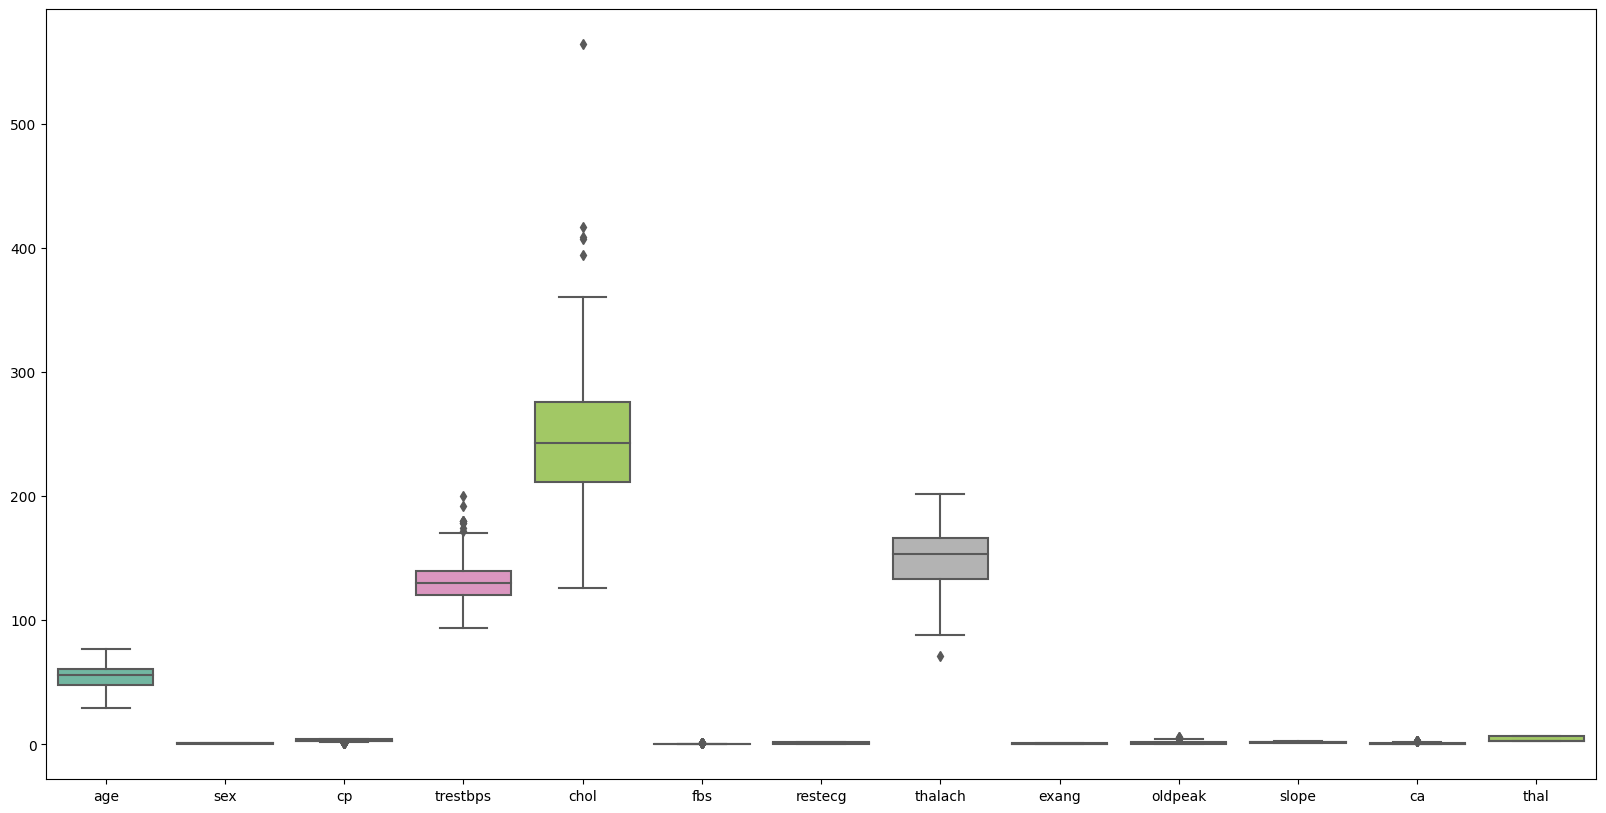

In [28]:
plt.figure(figsize=(20,10))
sns.boxplot(X, palette="Set2",)

## Split Dataset

In [29]:
X_train, X_valid, X_test, y_train, y_valid, y_test = train_validation_test_split(
    X, y, validation_size=0.15, test_size=0.15, random_state=random_state
)

In [30]:
X_train.shape, X_valid.shape, X_test.shape


((207, 13), (45, 13), (45, 13))

In [31]:
y_train.shape, y_valid.shape, y_test.shape

((207, 1), (45, 1), (45, 1))

In [32]:
y_train.value_counts(), y_valid.value_counts(), y_test.value_counts()

(num
 0      112
 1       38
 2       24
 3       24
 4        9
 Name: count, dtype: int64,
 num
 0      24
 1       8
 3       6
 2       5
 4       2
 Name: count, dtype: int64,
 num
 0      24
 1       8
 2       6
 3       5
 4       2
 Name: count, dtype: int64)

# Pre-processing

## Scaling the data

In [33]:
scaler_knn = MinMaxScaler()
scaler_lvq = MinMaxScaler()
scaler_dt = MinMaxScaler()
scaler_rf = MinMaxScaler()
scaler_ada = MinMaxScaler()
scaler_mlp = MinMaxScaler()

# Model

## KNN 

In [34]:
cv = StratifiedShuffleSplit(n_splits=50, test_size=0.2, random_state=random_state)
knn = KNeighborsClassifier()
scoring = {
    "Accuracy": "accuracy", "ROC-AUC": "roc_auc_ovr",
    "Precision": "precision_macro", "Recall": "recall_macro", "F1": "f1_macro",
}
knn_opt = BayesSearchCV(
    knn,
    {
        "n_neighbors": (1, 80),
        "weights": ["uniform", "distance"],
        "p": (1, 2, 3, 4, 5),
    },
    n_iter=25,
    cv=cv,
    n_jobs=-1,
    verbose=1,
    scoring=scoring,
    refit="Accuracy",
    random_state=random_state,
)

pipe_knn = Pipeline([("scaler", scaler_knn), ("knn", knn_opt)])

In [35]:
pipe_knn.fit(X_train, y_train["num"])

Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for eac

Pipeline(steps=[('scaler', MinMaxScaler()),
                ('knn',
                 BayesSearchCV(cv=StratifiedShuffleSplit(n_splits=50, random_state=42, test_size=0.2,
            train_size=None),
                               estimator=KNeighborsClassifier(), n_iter=25,
                               n_jobs=-1, random_state=42, refit='Accuracy',
                               scoring={'Accuracy': 'accuracy',
                                        'F1': 'f1_macro',
                                        'Precision': 'precision_macro',
                                        'ROC-AUC': 'roc_auc_ovr',
                                        'Recall': 'recall_macro'},
                               search_spaces={'n_neighbors': (1, 80),
                                              'p': (1, 2, 3, 4, 5),
                                              'weights': ['uniform',
                                                          'distance']},
                               verbose=1))])

Best parameters: OrderedDict([('n_neighbors', 64), ('p', 3), ('weights', 'distance')])
Cross Validation accuracy Array: [0.5952381  0.54761905 0.61904762 0.54761905 0.66666667 0.54761905
 0.57142857 0.61904762 0.54761905 0.64285714 0.61904762 0.5952381
 0.5952381  0.5952381  0.5952381  0.57142857 0.57142857 0.54761905
 0.5952381  0.5952381  0.5952381  0.61904762 0.61904762 0.5
 0.57142857 0.61904762 0.61904762 0.54761905 0.57142857 0.61904762
 0.57142857 0.54761905 0.57142857 0.5952381  0.57142857 0.64285714
 0.5952381  0.5952381  0.57142857 0.5952381  0.54761905 0.54761905
 0.5952381  0.54761905 0.57142857 0.5952381  0.57142857 0.54761905
 0.52380952 0.54761905]
Validation accuracy: 0.58238 ± 0.00939
Cross Validation precision Array: [0.19809524 0.1627451  0.41142857 0.13939394 0.38939394 0.17571429
 0.17105263 0.62222222 0.11794872 0.3647619  0.32941176 0.42432432
 0.3627451  0.3688172  0.27142857 0.16439394 0.35833333 0.11219512
 0.18857143 0.22321429 0.36386555 0.33333333 0.3019607

c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` param

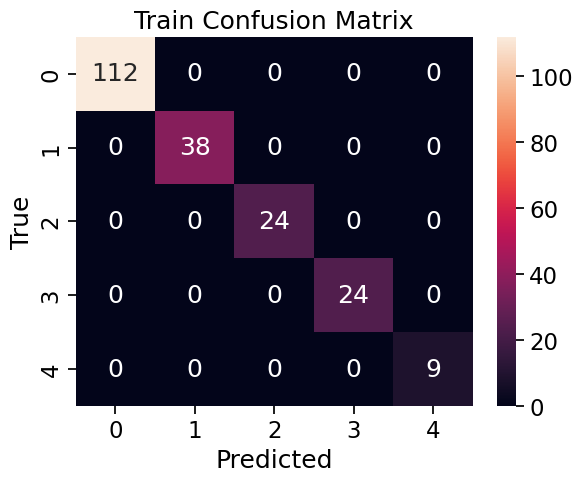

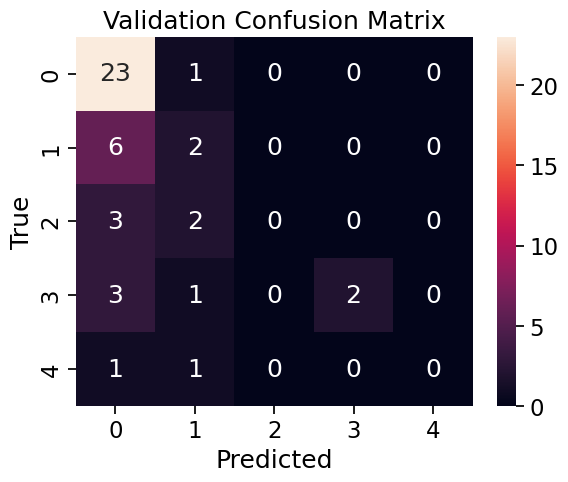

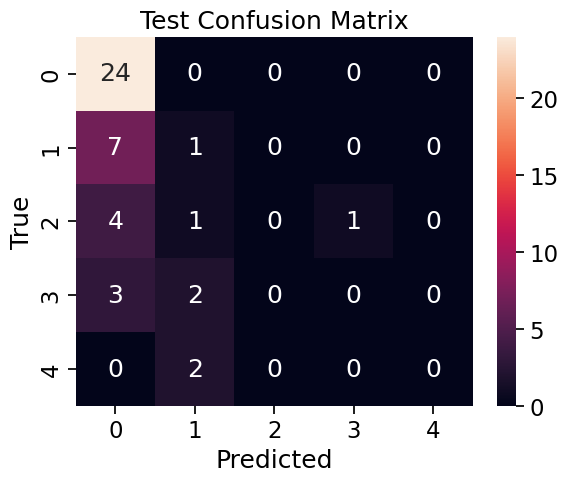

In [38]:
report_model_performance(pipe_knn, X_train, X_valid, X_test, y_train["num"], y_valid["num"], y_test["num"])

In [39]:
save_model(pipe_knn, "knn")

## LVQ

In [40]:
from skopt.space import Integer, Categorical

cv = StratifiedShuffleSplit(n_splits=5, test_size=0.2, random_state=random_state)
lvq = GLVQ(random_state=random_state)
scoring = {
    "Accuracy": "accuracy", "ROC-AUC": "roc_auc_ovr",
    "Precision": "precision_macro", "Recall": "recall_macro", "F1": "f1_macro",
}
lvq_opt = BayesSearchCV(
    lvq,
    {
        "prototype_n_per_class": (1,100),
        "distance_type": ["euclidean", "squared-euclidean"],
    },
    n_iter=4,
    cv=cv,
    n_jobs=-1,
    verbose=1,
    scoring=scoring,
    refit="Accuracy",
    random_state=random_state,
)

pipe_lvq = Pipeline([("scaler", scaler_lvq), ("lvq", lvq_opt)])

In [41]:
pipe_lvq.fit(X_train, y_train["num"])

Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits


Pipeline(steps=[('scaler', MinMaxScaler()),
                ('lvq',
                 BayesSearchCV(cv=StratifiedShuffleSplit(n_splits=5, random_state=42, test_size=0.2,
            train_size=None),
                               estimator=GLVQ(random_state=42), n_iter=4,
                               n_jobs=-1, random_state=42, refit='Accuracy',
                               scoring={'Accuracy': 'accuracy',
                                        'F1': 'f1_macro',
                                        'Precision': 'precision_macro',
                                        'ROC-AUC': 'roc_auc_ovr',
                                        'Recall': 'recall_macro'},
                               search_spaces={'distance_type': ['euclidean',
                                                                'squared-euclidean'],
                                              'prototype_n_per_class': (1,
                                                                        100)},
                               verbose=1))])

Best parameters: OrderedDict([('distance_type', 'squared-euclidean'), ('prototype_n_per_class', 88)])
Cross Validation accuracy Array: [0.47619048 0.5952381  0.52380952 0.61904762 0.47619048]
Validation accuracy: 0.53810 ± 0.08257
Cross Validation precision Array: [0.26857143 0.43333333 0.27948718 0.43214286 0.38509317]
Validation precision: 0.35973 ± 0.10021
Cross Validation recall Array: [0.25639752 0.42248447 0.33378882 0.47391304 0.29652174]
Validation recall: 0.35662 ± 0.11153
Cross Validation f1 Array: [0.25782207 0.42525253 0.29698238 0.44301476 0.32318841]
Validation f1: 0.34925 ± 0.10076
Cross Validation roc Array: [0.59600819 0.67395151 0.73963822 0.75155558 0.74164319]
Validation roc: 0.70056 ± 0.08202

===> Training performance
              precision    recall  f1-score   support

           0    0.82353   0.87500   0.84848       112
           1    0.48148   0.34211   0.40000        38
           2    0.52632   0.41667   0.46512        24
           3    0.54839   0.70833

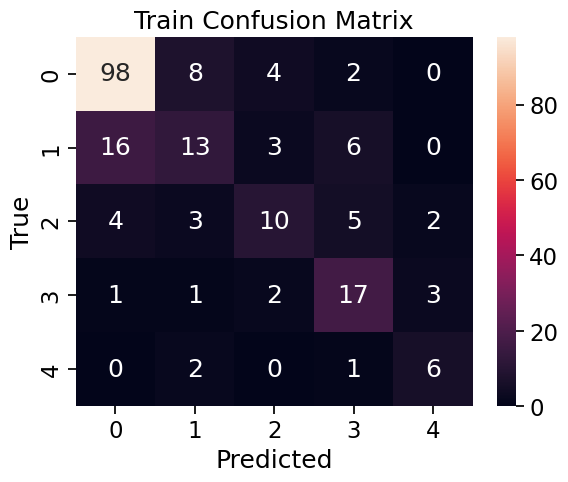

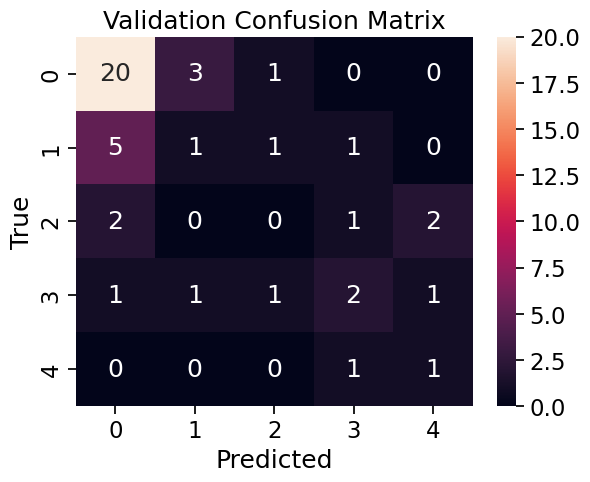

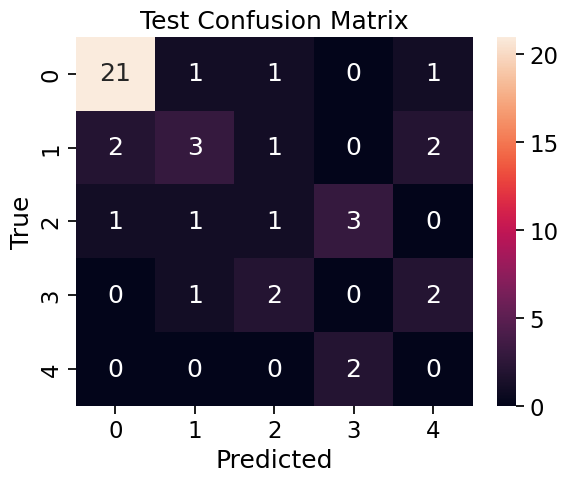

In [42]:
report_model_performance(pipe_lvq, X_train, X_valid, X_test, y_train["num"], y_valid["num"], y_test["num"])

In [43]:
save_model(pipe_lvq, "lvq")

## Decision Tree 

In [44]:
cv = StratifiedShuffleSplit(n_splits=50, test_size=0.2, random_state=random_state)
dt = DecisionTreeClassifier(random_state=random_state)
scoring = {
    "Accuracy": "accuracy", "ROC-AUC": "roc_auc_ovr",
    "Precision": "precision_macro", "Recall": "recall_macro", "F1": "f1_macro",
}
dt_opt = BayesSearchCV(
    dt,
    {
        "criterion": ["gini", "entropy"],
        "splitter": ["best", "random"],
        "max_depth": (1, 100),
        "min_samples_split": (2, 100),
        "min_samples_leaf": (1, 100),
    },
    n_iter=25,
    cv=cv,
    n_jobs=-1,
    verbose=1,
    scoring=scoring,
    refit="Accuracy",
    random_state=random_state,
)

pipe_dt = Pipeline([("scaler", scaler_dt), ("dt", dt_opt)])

In [45]:
pipe_dt.fit(X_train, y_train["num"])

Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for eac

Pipeline(steps=[('scaler', MinMaxScaler()),
                ('dt',
                 BayesSearchCV(cv=StratifiedShuffleSplit(n_splits=50, random_state=42, test_size=0.2,
            train_size=None),
                               estimator=DecisionTreeClassifier(random_state=42),
                               n_iter=25, n_jobs=-1, random_state=42,
                               refit='Accuracy',
                               scoring={'Accuracy': 'accuracy',
                                        'F1': 'f1_macro',
                                        'Precision': 'precision_macro',
                                        'ROC-AUC': 'roc_auc_ovr',
                                        'Recall': 'recall_macro'},
                               search_spaces={'criterion': ['gini', 'entropy'],
                                              'max_depth': (1, 100),
                                              'min_samples_leaf': (1, 100),
                                              'min_samples_split': (2, 100),
                                              'splitter': ['best', 'random']},
                               verbose=1))])

In [46]:
save_model(pipe_dt, "dt")

Best parameters: OrderedDict([('criterion', 'entropy'), ('max_depth', 94), ('min_samples_leaf', 17), ('min_samples_split', 20), ('splitter', 'random')])
Cross Validation accuracy Array: [0.57142857 0.57142857 0.57142857 0.54761905 0.52380952 0.54761905
 0.57142857 0.57142857 0.5952381  0.57142857 0.57142857 0.5952381
 0.61904762 0.38095238 0.5952381  0.54761905 0.54761905 0.52380952
 0.57142857 0.57142857 0.54761905 0.5952381  0.61904762 0.52380952
 0.54761905 0.5952381  0.54761905 0.57142857 0.54761905 0.57142857
 0.54761905 0.54761905 0.52380952 0.52380952 0.61904762 0.52380952
 0.54761905 0.57142857 0.54761905 0.57142857 0.47619048 0.52380952
 0.54761905 0.54761905 0.54761905 0.57142857 0.57142857 0.54761905
 0.57142857 0.57142857]
Validation accuracy: 0.55667 ± 0.01067
Cross Validation precision Array: [0.24791667 0.2488172  0.17142857 0.12777778 0.24269788 0.17184751
 0.17105263 0.24238095 0.20432432 0.16777778 0.22083333 0.26130952
 0.32941176 0.17371795 0.18857143 0.19238095 0.1

c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` param

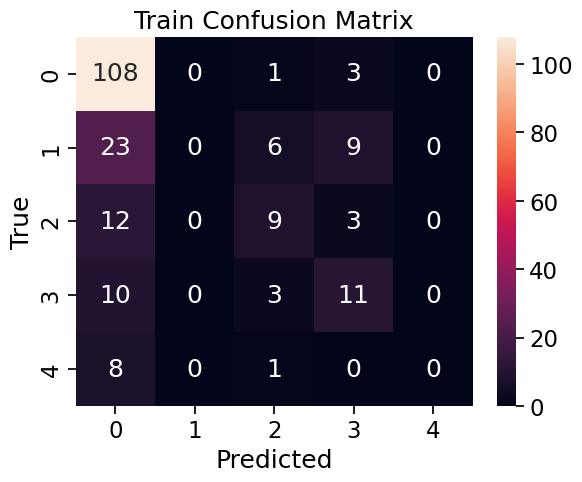

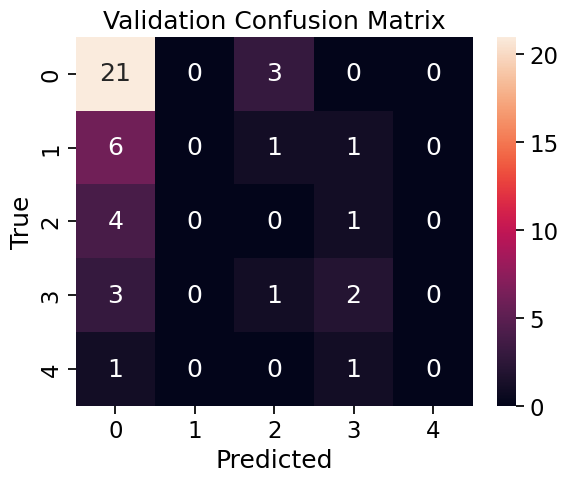

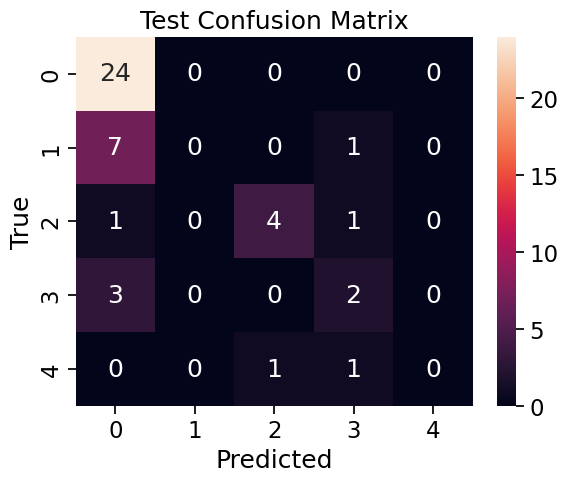

In [47]:
report_model_performance(pipe_dt, X_train, X_valid, X_test, y_train["num"], y_valid["num"], y_test["num"])

## Random Forest

In [48]:
cv = StratifiedShuffleSplit(n_splits=50, test_size=0.2, random_state=random_state)
rf = RandomForestClassifier(random_state=random_state)
scoring = {
    "Accuracy": "accuracy", "ROC-AUC": "roc_auc_ovr",
    "Precision": "precision_macro", "Recall": "recall_macro", "F1": "f1_macro",
}
rf_opt = BayesSearchCV(
    rf,
    {
        "n_estimators": (1, 1000),
        "criterion": ["gini", "entropy"],
        "max_depth": (1, 100),
        "min_samples_split": (2, 100),
        "min_samples_leaf": (1, 100),
        "max_features": Categorical([None, "sqrt", "log2"]),
    },
    n_iter=25,
    cv=cv,
    n_jobs=-1,
    verbose=1,
    scoring=scoring,
    refit="Accuracy",
    random_state=random_state,
)

pipe_rf = Pipeline([("scaler", scaler_rf), ("rfr", rf_opt)])

In [49]:
pipe_rf.fit(X_train, y_train["num"])

Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for eac

Pipeline(steps=[('scaler', MinMaxScaler()),
                ('rfr',
                 BayesSearchCV(cv=StratifiedShuffleSplit(n_splits=50, random_state=42, test_size=0.2,
            train_size=None),
                               estimator=RandomForestClassifier(random_state=42),
                               n_iter=25, n_jobs=-1, random_state=42,
                               refit='Accuracy',
                               scoring={'Accuracy': 'accuracy',
                                        'F1': 'f1_macro',
                                        'Precision': 'precision_macro',
                                        'ROC-AUC': 'roc_auc_ovr',
                                        'Recall': 'recall_macro'},
                               search_spaces={'criterion': ['gini', 'entropy'],
                                              'max_depth': (1, 100),
                                              'max_features': Categorical(categories=(None, 'sqrt', 'log2'), prior=None),
                                              'min_samples_leaf': (1, 100),
                                              'min_samples_split': (2, 100),
                                              'n_estimators': (1, 1000)},
                               verbose=1))])

In [50]:
save_model(pipe_rf, "rf")

Best parameters: OrderedDict([('criterion', 'gini'), ('max_depth', 50), ('max_features', 'sqrt'), ('min_samples_leaf', 1), ('min_samples_split', 2), ('n_estimators', 850)])
Cross Validation accuracy Array: [0.52380952 0.54761905 0.57142857 0.64285714 0.54761905 0.5
 0.5952381  0.5952381  0.61904762 0.5952381  0.57142857 0.61904762
 0.5952381  0.57142857 0.54761905 0.57142857 0.57142857 0.52380952
 0.5952381  0.61904762 0.57142857 0.57142857 0.5952381  0.54761905
 0.61904762 0.5952381  0.66666667 0.57142857 0.57142857 0.57142857
 0.61904762 0.54761905 0.54761905 0.5952381  0.64285714 0.5
 0.64285714 0.52380952 0.61904762 0.57142857 0.54761905 0.57142857
 0.54761905 0.54761905 0.5952381  0.57142857 0.5952381  0.52380952
 0.57142857 0.57142857]
Validation accuracy: 0.57714 ± 0.01046
Cross Validation precision Array: [0.23384615 0.1752381  0.24193548 0.3183908  0.20416667 0.22903226
 0.27083333 0.40215054 0.43333333 0.42796296 0.32       0.33529412
 0.33214286 0.36174056 0.2375     0.21041

c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` param

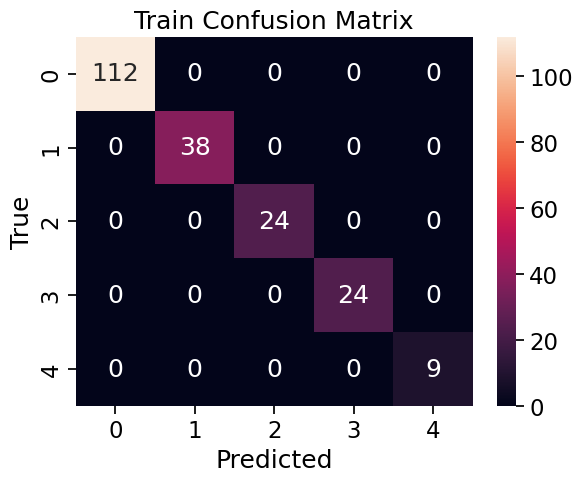

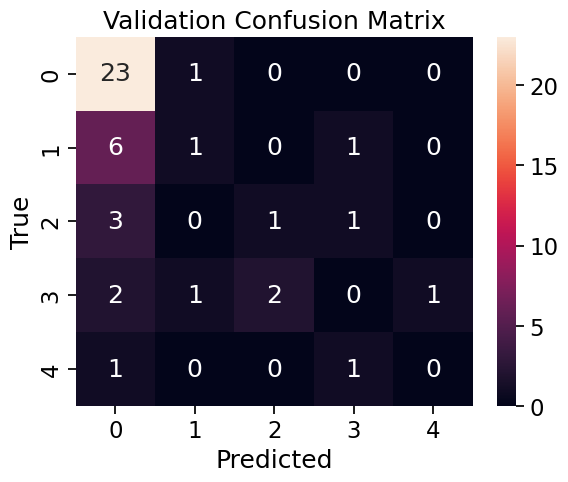

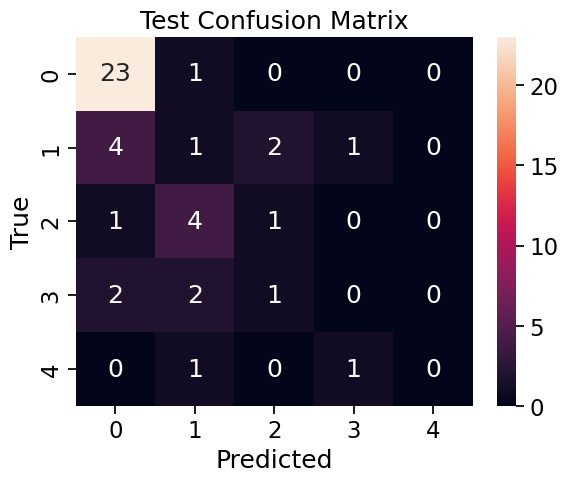

In [51]:
report_model_performance(pipe_rf, X_train, X_valid, X_test, y_train["num"], y_valid["num"], y_test["num"])

## AdaBoost

In [52]:
cv = StratifiedShuffleSplit(n_splits=50, test_size=0.2, random_state=random_state)
ada = AdaBoostClassifier(random_state=random_state)
scoring = {
    "Accuracy": "accuracy", "ROC-AUC": "roc_auc_ovr",
    "Precision": "precision_macro", "Recall": "recall_macro", "F1": "f1_macro",
}
ada_opt = BayesSearchCV(
    ada,
    {
        "n_estimators": (1, 1000),
        "learning_rate": (0.01, 1),
        "algorithm": ["SAMME", "SAMME.R"],
    },
    n_iter=25,
    cv=cv,
    n_jobs=-1,
    verbose=1,
    scoring=scoring,
    refit="Accuracy",
    random_state=random_state,
)

pipe_opt = Pipeline([("scaler", scaler_ada), ("ada", ada_opt)])

In [53]:
pipe_opt.fit(X_train, y_train["num"])

Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for eac

Pipeline(steps=[('scaler', MinMaxScaler()),
                ('ada',
                 BayesSearchCV(cv=StratifiedShuffleSplit(n_splits=50, random_state=42, test_size=0.2,
            train_size=None),
                               estimator=AdaBoostClassifier(random_state=42),
                               n_iter=25, n_jobs=-1, random_state=42,
                               refit='Accuracy',
                               scoring={'Accuracy': 'accuracy',
                                        'F1': 'f1_macro',
                                        'Precision': 'precision_macro',
                                        'ROC-AUC': 'roc_auc_ovr',
                                        'Recall': 'recall_macro'},
                               search_spaces={'algorithm': ['SAMME', 'SAMME.R'],
                                              'learning_rate': (0.01, 1),
                                              'n_estimators': (1, 1000)},
                               verbose=1))])

In [54]:
save_model(pipe_opt, "ada")

Best parameters: OrderedDict([('algorithm', 'SAMME'), ('learning_rate', 0.01), ('n_estimators', 1000)])
Cross Validation accuracy Array: [0.57142857 0.5952381  0.52380952 0.61904762 0.52380952 0.57142857
 0.5952381  0.64285714 0.57142857 0.5952381  0.64285714 0.61904762
 0.5952381  0.54761905 0.61904762 0.57142857 0.47619048 0.5952381
 0.5952381  0.61904762 0.5        0.61904762 0.69047619 0.54761905
 0.5        0.57142857 0.5952381  0.61904762 0.54761905 0.57142857
 0.5952381  0.57142857 0.52380952 0.5952381  0.57142857 0.54761905
 0.57142857 0.52380952 0.64285714 0.5952381  0.52380952 0.5952381
 0.5952381  0.47619048 0.64285714 0.64285714 0.66666667 0.52380952
 0.5952381  0.5952381 ]
Validation accuracy: 0.58095 ± 0.01346
Cross Validation precision Array: [0.33888889 0.30714286 0.28074074 0.22528736 0.1688172  0.37992832
 0.38       0.42445141 0.25666667 0.21333333 0.50606061 0.27219662
 0.2        0.23507389 0.30089286 0.19375    0.14814815 0.21904762
 0.20626959 0.30333333 0.165079

c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` param

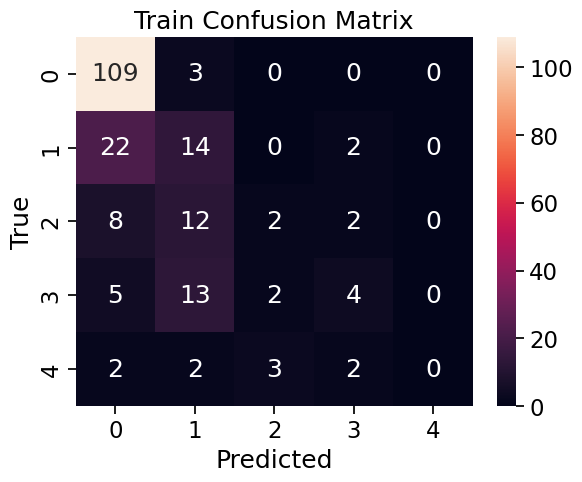

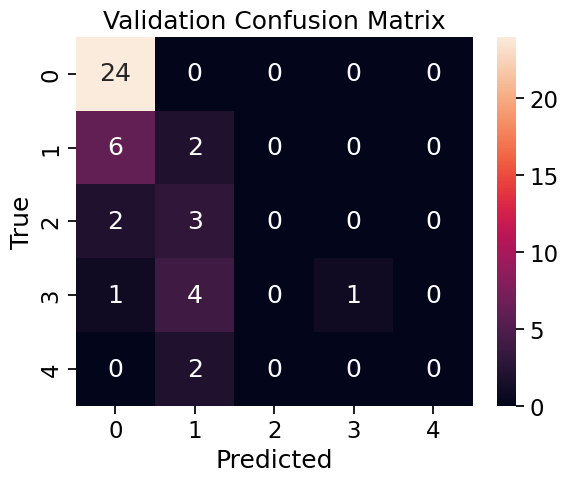

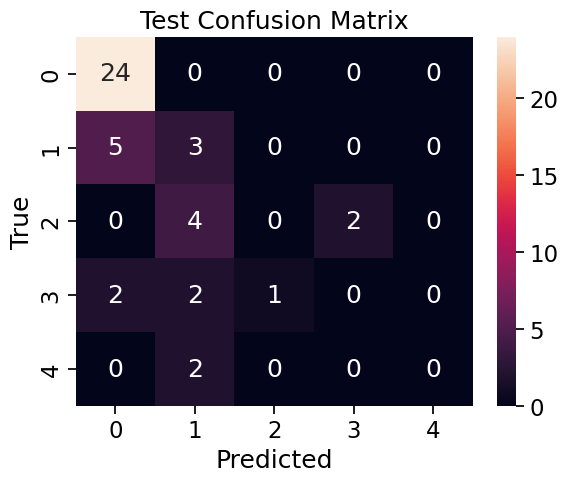

In [55]:
report_model_performance(pipe_opt, X_train, X_valid, X_test, y_train["num"], y_valid["num"], y_test["num"])

## MLP

In [56]:
cv = StratifiedShuffleSplit(n_splits=50, test_size=0.2, random_state=random_state)
mlp = MLPClassifier(random_state=random_state, max_iter=1000)
scoring = {
    "Accuracy": "accuracy", "ROC-AUC": "roc_auc_ovr",
    "Precision": "precision_macro", "Recall": "recall_macro", "F1": "f1_macro",
}
mlp_opt = RandomizedSearchCV(
    mlp,
    {
        "hidden_layer_sizes": [(5,), (10,), (5, 10), (10, 5), (10, 10)],
        "activation": ["identity", "logistic", "tanh", "relu"],
        "solver": ["lbfgs", "sgd", "adam"],
        "alpha": np.arange(0, 100),
        "learning_rate": ["constant", "invscaling", "adaptive"],
    },
    n_iter=25,
    cv=cv,
    n_jobs=-1,
    verbose=1,
    scoring=scoring,
    refit="Accuracy",
    random_state=random_state,
)

pipe_mlp = Pipeline([("scaler", scaler_mlp), ("mlp", mlp_opt)])

In [57]:
pipe_mlp.fit(X_train, y_train["num"])

Fitting 50 folds for each of 25 candidates, totalling 1250 fits


Pipeline(steps=[('scaler', MinMaxScaler()),
                ('mlp',
                 RandomizedSearchCV(cv=StratifiedShuffleSplit(n_splits=50, random_state=42, test_size=0.2,
            train_size=None),
                                    estimator=MLPClassifier(max_iter=1000,
                                                            random_state=42),
                                    n_iter=25, n_jobs=-1,
                                    param_distributions={'activation': ['identity',
                                                                        'logistic',
                                                                        'tanh',
                                                                        'relu'],
                                                         'alpha': array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14,...
       85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99]),
                                                         'hidden_layer_sizes': [(5,),
                                                                                (10,),
                                                                                (5,
                                                                                 10),
                                                                                (10,
                                                                                 5),
                                                                                (10,
                                                                                 10)],
                                                         'learning_rate': ['constant',
                                                                           'invscaling',
                                                                           'adaptive'],
                                                         'solver': ['lbfgs',
                                                                    'sgd',
                                                                    'adam']},
                                    random_state=42, refit='Accuracy',
                                    scoring={'Accuracy': 'accuracy',
                                             'F1': 'f1_macro',
                                             'Precision': 'precision_macro',
                                             'ROC-AUC': 'roc_auc_ovr',
                                             'Recall': 'recall_macro'},
                                    verbose=1))])

Best parameters: {'solver': 'lbfgs', 'learning_rate': 'constant', 'hidden_layer_sizes': (10,), 'alpha': 4, 'activation': 'identity'}
Cross Validation accuracy Array: [0.57142857 0.54761905 0.61904762 0.64285714 0.57142857 0.5952381
 0.57142857 0.5952381  0.61904762 0.66666667 0.64285714 0.64285714
 0.5952381  0.57142857 0.5952381  0.5952381  0.52380952 0.61904762
 0.57142857 0.54761905 0.52380952 0.5952381  0.61904762 0.5
 0.57142857 0.57142857 0.5952381  0.64285714 0.61904762 0.61904762
 0.57142857 0.47619048 0.52380952 0.61904762 0.66666667 0.64285714
 0.5952381  0.5952381  0.5952381  0.5952381  0.57142857 0.61904762
 0.5952381  0.61904762 0.54761905 0.5952381  0.64285714 0.52380952
 0.54761905 0.5       ]
Validation accuracy: 0.58810 ± 0.01240
Cross Validation precision Array: [0.27002165 0.22482759 0.39816092 0.29444444 0.2136289  0.29772727
 0.26793103 0.26269841 0.28860215 0.33439153 0.31984127 0.29505376
 0.27166667 0.4952862  0.24362519 0.22375    0.22833333 0.32215054
 0.27222

c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` param

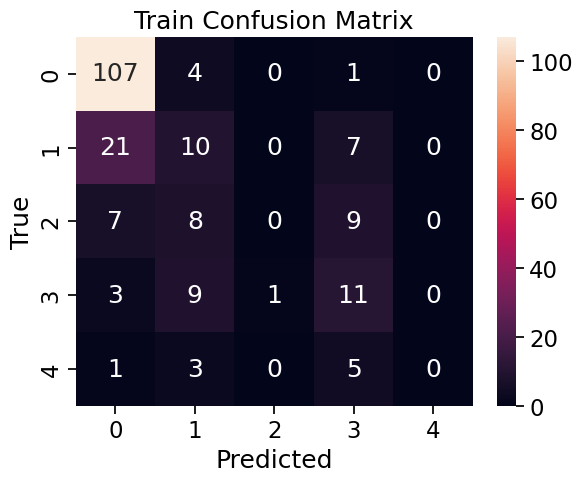

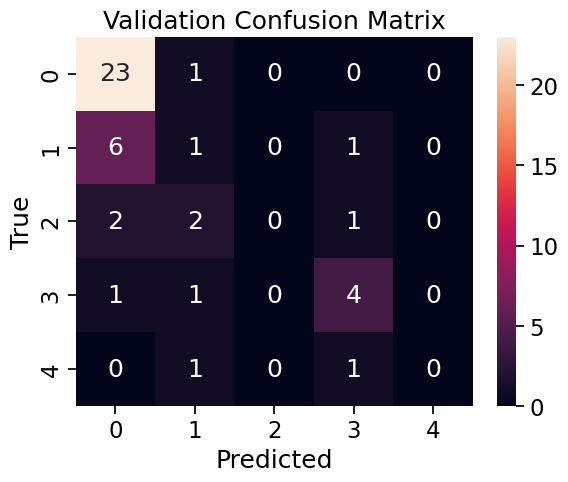

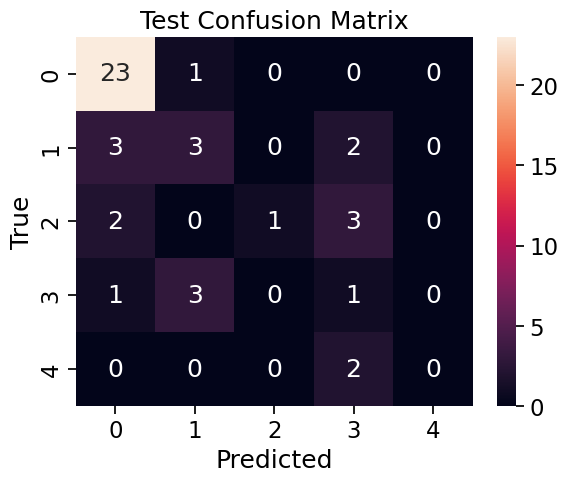

In [58]:
report_model_performance(pipe_mlp, X_train, X_valid, X_test, y_train["num"], y_valid["num"], y_test["num"])

In [59]:
save_model(pipe_mlp, "mlp")

## ELM